# Project 2: Digital Advertising Budget Optimizer
**Course:** Big Data Analytics  |  **Brand context:** Limelight (Pakistani fashion brand), continuing from Project 1 (Limelight YouTube analysis)

**Management question:** *Where should we spend the next Rs. 1 million?*

**Pipeline of this notebook**
1. Simulate advertising data (10k, 100k, 1M, 10M records) for Facebook, Instagram, Google, TikTok, YouTube
2. Compute marketing KPIs: CTR, CPC, CPA, conversion rate, ROAS, revenue
3. Compare Pandas vs MapReduce vs Spark as data grows
4. Build a Marketing Budget Recommendation Engine (diminishing-returns model + optimiser)
5. Validate the engine on held-out data and give a final recommendation

> **Important note:** all advertising data here is **simulated**. Limelight's real ad spend is not public. The simulator is *calibrated with assumptions* taken from Project 1 (e.g. Eid and Sale campaigns have high reach but weaker engagement; Unstitched/fabric content has the strongest engagement). Results show the *method*, not Limelight's actual numbers.

## Step 0: Setup

In [1]:
import os, time, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

SEED = 42
OUT_DIR = "data"            # simulated CSV files are saved here
os.makedirs(OUT_DIR, exist_ok=True)

# one colour per platform, fixed everywhere in the notebook
PLAT_COLORS = {"Facebook": "#2a78d6", "Instagram": "#e87ba4", "Google": "#eda100",
               "TikTok": "#1baf7a", "YouTube": "#eb6834"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})

## Step 1: Simulator (the "ground truth" of our fake market)
Each record = one ad line-item (a campaign shown on one platform on one day to one audience segment).
Every platform has its own cost per 1000 impressions (CPM), click rate, conversion rate and **saturation** (diminishing returns: the more you spend in a week on one platform, the worse each extra rupee performs).
Because *we* wrote these numbers, later we can check whether the engine recovers them.

In [2]:
PLATFORMS = ["Facebook", "Instagram", "Google", "TikTok", "YouTube"]
CAMPAIGNS = ["Eid Collection", "Unstitched Fabric", "Pret Wear", "Winter Collection", "Sale", "Accessories"]
AGES      = ["18-24", "25-34", "35-44", "45+"]
GENDERS   = ["Female", "Male"]
CITIES    = ["Karachi", "Lahore", "Islamabad", "Rawalpindi", "Faisalabad", "Multan", "Peshawar", "Other"]
DEVICES   = ["Mobile", "Desktop", "Tablet"]

# platform: row share, CPM (Rs per 1000 impr.), base CTR, base conversion rate (per click), saturation gamma
PLAT = {
    "Facebook":  dict(share=.28, cpm=320, ctr=.012, cvr=.012, gamma=.35),
    "Instagram": dict(share=.26, cpm=420, ctr=.015, cvr=.015, gamma=.30),
    "Google":    dict(share=.20, cpm=650, ctr=.028, cvr=.022, gamma=.50),
    "TikTok":    dict(share=.14, cpm=240, ctr=.010, cvr=.009, gamma=.20),
    "YouTube":   dict(share=.12, cpm=300, ctr=.006, cvr=.011, gamma=.25),
}
# campaign: impression multiplier, CTR multiplier, CVR multiplier, order-value multiplier  (from Project 1 findings)
CAMP = {
    "Eid Collection":    (1.6, .80, .80, 1.2),   # high reach, low engagement
    "Unstitched Fabric": (1.0, 1.25, 1.25, 1.0), # best engagement
    "Pret Wear":         (1.0, 1.00, 1.00, 1.3),
    "Winter Collection": (1.0, 1.00, 1.10, 1.4),
    "Sale":              (1.5, .85, .85, .8),    # high reach, low engagement
    "Accessories":       (.8, 1.00, 1.00, .5),
}
AGE_P  = [.25, .40, .25, .10];  AGE_M  = {"18-24": (1.2, .8), "25-34": (1.0, 1.2), "35-44": (.9, 1.2), "45+": (.7, 1.0)}
GEN_P  = [.80, .20];            GEN_M  = {"Female": (1.0, 1.0), "Male": (.6, .7)}
CITY_P = [.28, .27, .12, .06, .08, .06, .06, .07]
CITY_M = {"Karachi": 1.1, "Lahore": 1.1, "Islamabad": 1.05, "Rawalpindi": 1.0, "Faisalabad": .95, "Multan": .9, "Peshawar": .9, "Other": .8}
DEV_P  = [.70, .20, .10];       DEV_M  = {"Mobile": (1.0, .9), "Desktop": (.8, 1.3), "Tablet": (.9, 1.0)}
BASE_AOV = 4500  # average order value in Rs

# which campaigns run in which month (rows = Jan..Dec)
W = np.ones((12, 6)) * .15
W[[2, 3, 5], 0] += .30                 # Eid: Mar, Apr, Jun
W[[9, 10, 11, 0], 3] += .35            # Winter: Oct-Jan
W[[0, 6, 10, 11], 4] += .30            # Sale: Jan, Jul, Nov, Dec
W[[1, 2, 3, 4, 7, 8], 1] += .20        # Unstitched: spring/summer
CAMP_CUM = (W / W.sum(1, keepdims=True)).cumsum(1)


def generate(n, seed=SEED, year=2025):
    """Return a DataFrame with n simulated ad records (fully vectorised)."""
    rng = np.random.default_rng(seed)
    day = rng.integers(0, 365, n)
    month = pd.to_datetime(day, unit="D", origin=f"{year}-01-01").month.values - 1
    week = day // 7

    plat_i = rng.choice(5, n, p=[PLAT[p]["share"] for p in PLATFORMS])
    camp_i = (rng.random(n)[:, None] > CAMP_CUM[month]).sum(1).clip(0, 5)
    age_i, gen_i = rng.choice(4, n, p=AGE_P), rng.choice(2, n, p=GEN_P)
    city_i, dev_i = rng.choice(8, n, p=CITY_P), rng.choice(3, n, p=DEV_P)

    # weekly "spend intensity" per platform -> creates diminishing returns
    m = np.exp(rng.normal(0, .45, (5, 53)) - .45 ** 2 / 2)[plat_i, week]

    cpm   = np.array([PLAT[p]["cpm"]   for p in PLATFORMS])[plat_i]
    ctr0  = np.array([PLAT[p]["ctr"]   for p in PLATFORMS])[plat_i]
    cvr0  = np.array([PLAT[p]["cvr"]   for p in PLATFORMS])[plat_i]
    gamma = np.array([PLAT[p]["gamma"] for p in PLATFORMS])[plat_i]
    cm = np.array([CAMP[c] for c in CAMPAIGNS])[camp_i]
    am = np.array([AGE_M[a] for a in AGES])[age_i]
    gm = np.array([GEN_M[g] for g in GENDERS])[gen_i]
    dm = np.array([DEV_M[d] for d in DEVICES])[dev_i]
    cym = np.array([CITY_M[c] for c in CITIES])[city_i]

    impressions = (1500 * cm[:, 0] * m * np.exp(rng.normal(0, .5, n) - .125)).astype(np.int64) + 1
    spend = impressions / 1000 * cpm * np.exp(rng.normal(0, .10, n))

    sat = m ** (-gamma / 2)                      # saturation on both CTR and CVR
    ctr = np.clip(ctr0 * cm[:, 1] * am[:, 0] * gm[:, 0] * dm[:, 0] * sat, 0, .5)
    cvr = np.clip(cvr0 * cm[:, 2] * am[:, 1] * gm[:, 1] * dm[:, 1] * cym * sat, 0, .5)
    clicks = rng.binomial(impressions, ctr)
    conversions = rng.binomial(clicks, cvr)
    aov = BASE_AOV * cm[:, 3] * np.exp(rng.normal(0, .35, n) - .35 ** 2 / 2)
    revenue = conversions * aov

    return pd.DataFrame({
        "date": pd.to_datetime(day, unit="D", origin=f"{year}-01-01"),
        "campaign": pd.Categorical.from_codes(camp_i, CAMPAIGNS),
        "platform": pd.Categorical.from_codes(plat_i, PLATFORMS),
        "impressions": impressions.astype(np.int32),
        "clicks": clicks.astype(np.int32),
        "spend": spend.round(2),
        "conversions": conversions.astype(np.int32),
        "revenue": revenue.round(2),
        "age": pd.Categorical.from_codes(age_i, AGES),
        "gender": pd.Categorical.from_codes(gen_i, GENDERS),
        "city": pd.Categorical.from_codes(city_i, CITIES),
        "device": pd.Categorical.from_codes(dev_i, DEVICES),
    })

df10k = generate(10_000)
df10k.head()

,date,campaign,platform,impressions,clicks,spend,conversions,revenue,age,gender,city,device
0,2025-02-02,Unstitched Fabric,Facebook,1379,15,416.51,0,0.00,45+,Female,Rawalpindi,Mobile
1,2025-10-10,Eid Collection,Google,5305,77,3835.42,2,25363.05,45+,Female,Faisalabad,Mobile
2,2025-08-27,Unstitched Fabric,TikTok,2615,31,640.65,1,3076.30,35-44,Female,Lahore,Mobile
3,2025-06-10,Sale,Facebook,495,5,153.14,0,0.00,25-34,Female,Karachi,Desktop
4,2025-06-08,Unstitched Fabric,Facebook,165,1,59.93,0,0.00,25-34,Female,Karachi,Desktop


## Step 2: KPI formulas
| KPI | Formula | Meaning |
|---|---|---|
| CTR | clicks / impressions | how attractive is the ad |
| CPC | spend / clicks | cost of one visit |
| Conversion rate | conversions / clicks | how many visits become orders |
| CPA | spend / conversions | cost of one order |
| ROAS | revenue / spend | Rs earned per Rs 1 of ads |

**Important:** KPIs of a *group* must be computed from the **sums** (e.g. total clicks / total impressions), never by averaging row-level CTRs.

In [3]:
def add_kpis(g):
    """g = DataFrame holding summed impressions, clicks, spend, conversions, revenue."""
    g = g.copy()
    g["CTR"]  = g["clicks"] / g["impressions"]
    g["CPC"]  = g["spend"] / g["clicks"]
    g["CVR"]  = g["conversions"] / g["clicks"]
    g["CPA"]  = g["spend"] / g["conversions"]
    g["ROAS"] = g["revenue"] / g["spend"]
    return g

SUM_COLS = ["impressions", "clicks", "spend", "conversions", "revenue"]
by_platform = add_kpis(df10k.groupby("platform", observed=True)[SUM_COLS].sum())
by_platform.round(4)

,impressions,clicks,spend,conversions,revenue,CTR,CPC,CVR,CPA,ROAS
platform,,,,,,,,,,
Facebook,5330896,51219,1709041.72,659,3119477.50,0.0096,33.3673,0.0129,2593.3865,1.8253
Instagram,4226365,52625,1783107.28,832,4050492.32,0.0125,33.8833,0.0158,2143.1578,2.2716
Google,3578788,82871,2328128.82,1861,8860114.61,0.0232,28.0934,0.0225,1251.0096,3.8057
TikTok,2841345,22550,688867.89,209,1002903.22,0.0079,30.5485,0.0093,3296.0186,1.4559
YouTube,2096582,10266,632891.72,119,593397.28,0.0049,61.6493,0.0116,5318.4178,0.9376


In [20]:
by_campaign = add_kpis(df10k.groupby("campaign", observed=True)[SUM_COLS].sum()).sort_values("ROAS", ascending=False)
by_campaign[["spend", "revenue", "CTR", "CVR", "CPA", "ROAS"]].round(4)

,spend,revenue,CTR,CVR,CPA,ROAS
campaign,,,,,,
Winter Collection,1215073.10,4707539.05,0.0130,0.0188,1641.9907,3.8743
Unstitched Fabric,1194448.55,4502379.16,0.0157,0.0211,1186.1455,3.7694
Pret Wear,684756.00,1944368.16,0.0125,0.0153,2025.9053,2.8395
Eid Collection,1745112.04,3331702.24,0.0102,0.0135,2879.7228,1.9092
Sale,1733568.04,2448124.43,0.0108,0.0147,2508.7815,1.4122
Accessories,569079.70,692271.89,0.0127,0.0162,1909.6634,1.2165


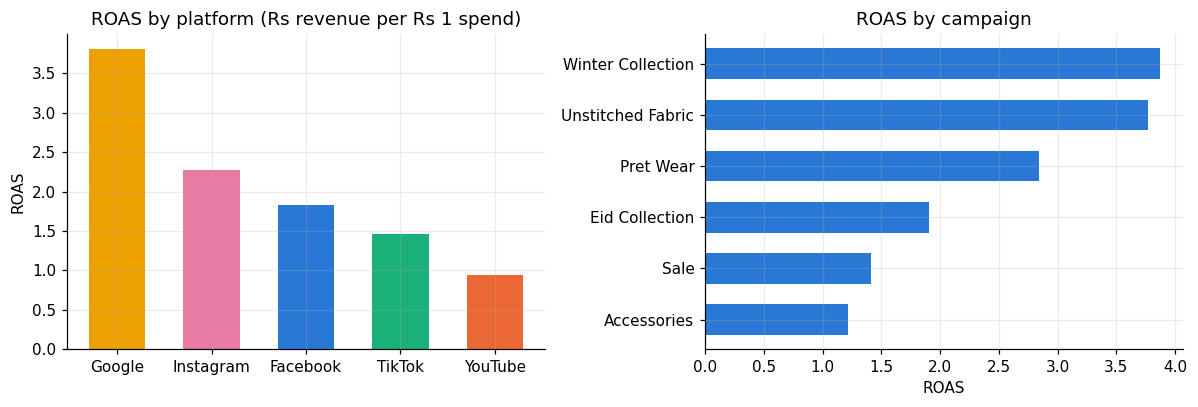

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
bp = by_platform.sort_values("ROAS", ascending=False)
ax[0].bar(bp.index, bp["ROAS"], color=[PLAT_COLORS[p] for p in bp.index], width=.6)
ax[0].set_title("ROAS by platform (Rs revenue per Rs 1 spend)"); ax[0].set_ylabel("ROAS")
bc = by_campaign
ax[1].barh(bc.index[::-1], bc["ROAS"][::-1], color="#2a78d6", height=.6)
ax[1].set_title("ROAS by campaign"); ax[1].set_xlabel("ROAS")
plt.tight_layout(); plt.show()

**Reading:** Compare platforms on *ROAS* and *CPA* together. Google has the highest ROAS but it is demand-limited (saturates quickly), so ROAS alone is not enough to decide the budget. That is why Step 4 models diminishing returns.

## Step 3: Big Data simulation, Pandas vs MapReduce vs Spark
We generate 10k, 100k, 1M and 10M records, save each as CSV, then run the **same job** with three engines:
> *Total impressions, clicks, spend, conversions, revenue per (platform, campaign), then KPIs.*

* **Pandas**: single machine, in-memory (`read_csv` + `groupby`)
* **MapReduce**: a real *map -> shuffle -> reduce* implementation in pure Python (multiprocessing). Each worker reads a byte-range *split* of the file and emits partial sums per key (map + combiner); the reducer merges them.
* **Spark**: PySpark `read.csv` + `groupBy` (distributed engine, run locally here)

In [4]:
SIZES = [10_000, 100_000, 1_000_000, 10_000_000]
paths, gen_time = {}, {}
for n in SIZES:
    p = f"{OUT_DIR}/ads_{n}.csv"
    paths[n] = p
    if not os.path.exists(p):
        t = time.time(); d = generate(n, seed=SEED + n % 97)
        gen_time[n] = time.time() - t
        d.to_csv(p, index=False); del d
    print(f"{n:>10,} rows  ->  {p}  ({os.path.getsize(p)/1e6:,.1f} MB)")

    10,000 rows  ->  data/ads_10000.csv  (0.8 MB)
   100,000 rows  ->  data/ads_100000.csv  (8.2 MB)
 1,000,000 rows  ->  data/ads_1000000.csv  (82.2 MB)
10,000,000 rows  ->  data/ads_10000000.csv  (822.0 MB)


In [5]:
# ---------- Engine 1: Pandas ----------
def job_pandas(path):
    d = pd.read_csv(path, usecols=["platform", "campaign"] + SUM_COLS,
                    dtype={"platform": "category", "campaign": "category"})
    g = d.groupby(["platform", "campaign"], observed=True)[SUM_COLS].sum()
    return add_kpis(g)

# ---------- Engine 2: MapReduce (pure python) ----------
from multiprocessing import Pool
from collections import defaultdict

HEADER = "date,campaign,platform,impressions,clicks,spend,conversions,revenue,age,gender,city,device".split(",")
IC, IP = HEADER.index("campaign"), HEADER.index("platform")
IV = [HEADER.index(c) for c in SUM_COLS]

def splits(path, k):
    size = os.path.getsize(path); step = size // k
    return [(path, i * step, size if i == k - 1 else (i + 1) * step) for i in range(k)]

def map_task(args):
    """MAP + COMBINE: read lines of one split, emit {(platform, campaign): [sums]}"""
    path, start, end = args
    acc = defaultdict(lambda: [0.0] * 5)
    with open(path, "rb") as f:
        if start == 0:
            f.readline()               # skip header
        else:
            f.seek(start - 1); f.readline()   # align to next full line
        while f.tell() < end:
            line = f.readline()
            if not line: break
            x = line.decode().rstrip("\n").split(",")
            a = acc[(x[IP], x[IC])]
            for j, i in enumerate(IV):
                a[j] += float(x[i])
    return dict(acc)

def job_mapreduce(path, workers=None):
    workers = workers or os.cpu_count()
    with Pool(workers) as pool:
        partials = pool.map(map_task, splits(path, workers))      # MAP
    final = defaultdict(lambda: [0.0] * 5)                        # SHUFFLE + REDUCE
    for part in partials:
        for key, vals in part.items():
            for j in range(5): final[key][j] += vals[j]
    g = pd.DataFrame.from_dict(final, orient="index", columns=SUM_COLS)
    g.index = pd.MultiIndex.from_tuples(g.index, names=["platform", "campaign"])
    return add_kpis(g.sort_index())

# ---------- Engine 3: Spark ----------
def job_spark(path, spark):
    from pyspark.sql import functions as F
    d = spark.read.csv(path, header=True, inferSchema=True)
    g = d.groupBy("platform", "campaign").agg(*[F.sum(c).alias(c) for c in SUM_COLS])
    g = (g.withColumn("CTR", F.col("clicks") / F.col("impressions"))
           .withColumn("CPC", F.col("spend") / F.col("clicks"))
           .withColumn("CVR", F.col("conversions") / F.col("clicks"))
           .withColumn("CPA", F.col("spend") / F.col("conversions"))
           .withColumn("ROAS", F.col("revenue") / F.col("spend")))
    return g.toPandas()          # toPandas forces the computation (30 rows only)

In [6]:
# sanity check: all engines must give the same answer on a small file
a = job_pandas(paths[10_000]).sort_index()
b = job_mapreduce(paths[10_000]).sort_index()
print("Pandas vs MapReduce identical results:", np.allclose(a[SUM_COLS].values, b[SUM_COLS].values))

Pandas vs MapReduce identical results: True


In [7]:
HAVE_SPARK = False
try:
    try:
        from pyspark.sql import SparkSession
    except ImportError:
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark"], check=True)
        from pyspark.sql import SparkSession
    spark = (SparkSession.builder.master("local[*]").appName("AdBudget")
             .config("spark.ui.showConsoleProgress", "false").getOrCreate())
    job_spark(paths[10_000], spark)       # warm-up (JVM start-up is not part of the job)
    HAVE_SPARK = True
except Exception as e:
    print("Spark not available in this environment:", type(e).__name__, "- run this notebook in Google Colab to include Spark.")

In [8]:
rows = []
for n in SIZES:
    r = {"records": n}
    for name, fn in [("Pandas", lambda p: job_pandas(p)), ("MapReduce", lambda p: job_mapreduce(p))] + \
                    ([("Spark", lambda p: job_spark(p, spark))] if HAVE_SPARK else []):
        t = time.time(); fn(paths[n]); r[name] = round(time.time() - t, 2)
    rows.append(r)
bench = pd.DataFrame(rows).set_index("records")
bench.to_csv("benchmark_seconds.csv")
bench

,Pandas,MapReduce,Spark
records,,,
10000,0.03,0.06,1.63
100000,0.17,0.29,2.62
1000000,1.33,2.75,9.58
10000000,14.04,30.35,65.89


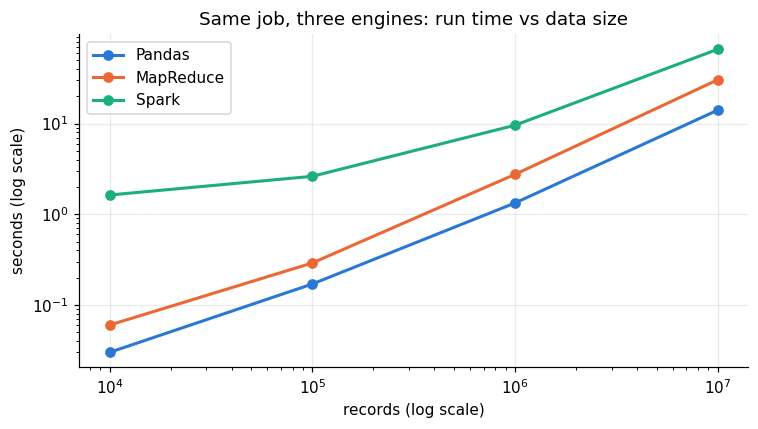

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
cols = {"Pandas": "#2a78d6", "MapReduce": "#eb6834", "Spark": "#1baf7a"}
for c in bench.columns:
    ax.plot(bench.index, bench[c], marker="o", lw=2, color=cols[c], label=c)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("records (log scale)"); ax.set_ylabel("seconds (log scale)")
ax.set_title("Same job, three engines: run time vs data size"); ax.legend()
plt.tight_layout(); plt.show()

**How to read the benchmark** (fill in the sentences with your own measured numbers)
* On a single machine (laptop or Colab) Pandas is expected to be fastest at every size here, even at 10M rows, because the data still fits in RAM and Pandas has almost no start-up cost.
* Spark and MapReduce pay a fixed overhead (JVM start-up, process pool, task scheduling). That overhead is visible on small files and is amortised on big ones, so their curves are flatter.
* Pure-Python MapReduce is slower per row because it parses text line by line, but it is the clearest illustration of *map -> shuffle -> reduce*.
* Where Spark really wins is **beyond one machine**: Pandas needs the whole dataset in RAM (10M rows is about 1 GB here, but 1B rows would fail), while Spark spreads data over many machines and spills to disk. A one-machine experiment cannot show this part, so the honest conclusion is: *Pandas is enough up to 10M rows; Spark/MapReduce are needed when data no longer fits in one machine's memory.*

## Step 4: Marketing Budget Recommendation Engine
**Idea:** Average ROAS tells us how good the *past* rupees were. To decide the *next* Rs 1M we need the **marginal** return, i.e. what the next rupee earns, because every platform saturates.

1. Aggregate history to **platform x week** (spend and revenue).
2. Fit a response curve per platform: `revenue = a * spend^b` (a straight line in log-log space). `b < 1` means diminishing returns.
3. Marginal ROAS = `a * b * spend^(b-1)`.
4. Allocate Rs 1M in small steps (Rs 10,000), each step to the platform with the highest marginal ROAS (optimal for concave curves).
5. Compare against simple strategies (equal split, current split, "all on highest ROAS").

We use the 100k-record year: its weekly spend per platform is of the same size as the Rs 1M decision, so the curves are valid in the range we use them.

In [10]:
hist = pd.read_csv(paths[100_000], parse_dates=["date"])
hist["week"] = hist["date"].dt.dayofyear // 7
wk = hist.groupby(["platform", "week"])[["spend", "revenue"]].sum().reset_index()
print(f"Total spend in history: Rs {hist['spend'].sum():,.0f} | average weekly spend: Rs {hist['spend'].sum()/53:,.0f}")
print("Weekly platform-level observations:", len(wk))

Total spend in history: Rs 68,157,201 | average weekly spend: Rs 1,285,985
Weekly platform-level observations: 265


In [11]:
def fit_curves(wk):
    out = {}
    for p, g in wk.groupby("platform", observed=True):
        x, y = np.log(g["spend"].values), np.log(g["revenue"].values)
        b, loga = np.polyfit(x, y, 1)
        r2 = np.corrcoef(x, y)[0, 1] ** 2
        out[p] = dict(a=math.exp(loga), b=b, r2=r2, avg_week_spend=g["spend"].mean())
    return pd.DataFrame(out).T

curves = fit_curves(wk)
curves["true_b (1 - gamma)"] = [1 - PLAT[p]["gamma"] for p in curves.index]
curves.round(3)

,a,b,r2,avg_week_spend,true_b (1 - gamma)
Facebook,169.796,0.641,0.787,308773.609,0.65
Google,1059.457,0.568,0.747,415148.680,0.50
Instagram,32.681,0.790,0.856,335203.546,0.70
TikTok,31.453,0.741,0.736,111221.581,0.80
YouTube,41.774,0.670,0.438,115637.508,0.75


**Check:** the fitted exponent `b` should be close to `1 - gamma` that we hard-coded in the simulator. If it is, the engine can "discover" the saturation pattern from data alone, which is what it would have to do with real data.

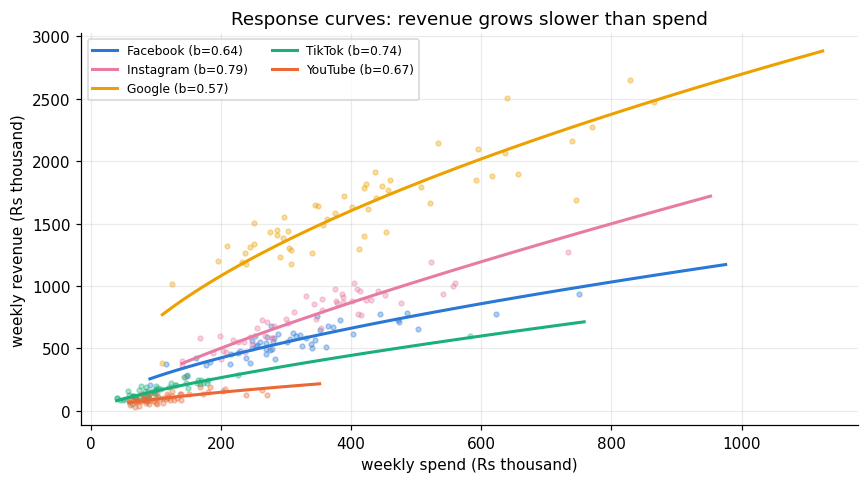

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for p in PLATFORMS:
    c = curves.loc[p]
    xs = np.linspace(wk[wk.platform == p]["spend"].min(), wk[wk.platform == p]["spend"].max() * 1.3, 100)
    ax.scatter(wk[wk.platform == p]["spend"] / 1e3, wk[wk.platform == p]["revenue"] / 1e3, s=10, alpha=.35, color=PLAT_COLORS[p])
    ax.plot(xs / 1e3, c.a * xs ** c.b / 1e3, color=PLAT_COLORS[p], lw=2, label=f"{p} (b={c.b:.2f})")
ax.set_xlabel("weekly spend (Rs thousand)"); ax.set_ylabel("weekly revenue (Rs thousand)")
ax.set_title("Response curves: revenue grows slower than spend"); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

In [13]:
def revenue_of(alloc, curves):
    """Predicted weekly revenue for a dict {platform: weekly spend}."""
    return sum(curves.loc[p, "a"] * alloc[p] ** curves.loc[p, "b"] for p in alloc if alloc[p] > 0)

def optimise(budget, curves, base=None, step=10_000):
    """Greedy marginal-ROAS allocation of `budget` on top of optional base spend per platform."""
    base = base or {p: curves.loc[p, "avg_week_spend"] for p in curves.index}
    extra = {p: 0.0 for p in curves.index}
    for _ in range(int(budget // step)):
        def marginal(p):
            s = base[p] + extra[p] + step / 2
            return curves.loc[p, "a"] * curves.loc[p, "b"] * s ** (curves.loc[p, "b"] - 1)
        best = max(curves.index, key=marginal)
        extra[best] += step
    return extra

BUDGET = 1_000_000
base = {p: curves.loc[p, "avg_week_spend"] for p in curves.index}
extra = optimise(BUDGET, curves, base)
base_rev = revenue_of(base, curves)
new_rev = revenue_of({p: base[p] + extra[p] for p in base}, curves)

reco = pd.DataFrame({"extra_spend_Rs": pd.Series(extra),
                     "share_%": pd.Series(extra) / BUDGET * 100,
                     "marginal_ROAS_at_new_level": [curves.loc[p, "a"] * curves.loc[p, "b"] * (base[p] + extra[p]) ** (curves.loc[p, "b"] - 1) for p in curves.index]})
reco = reco.loc[PLATFORMS]
print(f"Incremental revenue expected from the extra Rs {BUDGET:,}: Rs {new_rev - base_rev:,.0f}  (incremental ROAS {(new_rev - base_rev)/BUDGET:.2f})")
reco.round(2)

Incremental revenue expected from the extra Rs 1,000,000: Rs 1,730,450  (incremental ROAS 1.73)


,extra_spend_Rs,share_%,marginal_ROAS_at_new_level
Facebook,0.0,0.0,1.16
Instagram,390000.0,39.0,1.51
Google,610000.0,61.0,1.51
TikTok,0.0,0.0,1.15
YouTube,0.0,0.0,0.59


### Is the recommendation stable? (bootstrap)
A greedy optimiser can jump to an all-or-nothing answer when two platforms are close. To test stability we resample the weeks 200 times, refit the curves and re-optimise each time. The **average share** over the 200 runs is a more robust recommendation than a single run.

In [14]:
rng_b = np.random.default_rng(7)
shares = []
for _ in range(200):
    idx = rng_b.integers(0, len(wk), len(wk))
    try:
        cb = fit_curves(wk.iloc[idx])
        eb = optimise(BUDGET, cb, {p: cb.loc[p, "avg_week_spend"] for p in cb.index}, step=20_000)
        shares.append(pd.Series(eb) / BUDGET * 100)
    except Exception:
        pass
shares = pd.DataFrame(shares)[PLATFORMS]
stable = pd.DataFrame({"mean_share_%": shares.mean(), "p10_%": shares.quantile(.1), "p90_%": shares.quantile(.9),
                       "times_chosen_%": (shares > 0).mean() * 100}).round(1)
print(f"Bootstrap runs used: {len(shares)}")
stable

Bootstrap runs used: 200


,mean_share_%,p10_%,p90_%,times_chosen_%
Facebook,0.2,0.0,0.0,3.0
Instagram,41.9,0.0,84.2,85.0
Google,57.9,15.8,100.0,98.5
TikTok,0.0,0.0,0.0,0.5
YouTube,0.0,0.0,0.0,0.0


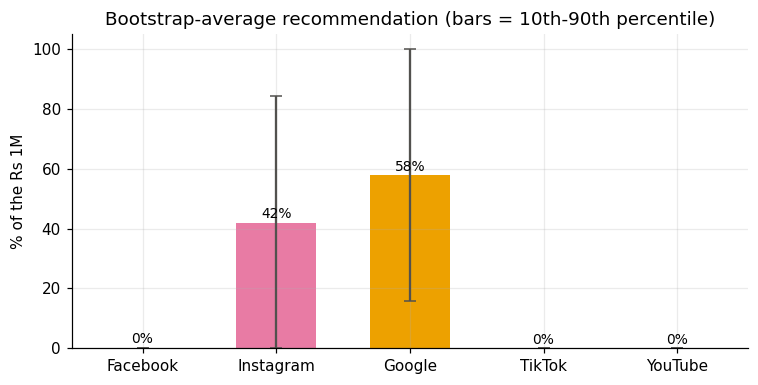

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(stable.index, stable["mean_share_%"], color=[PLAT_COLORS[p] for p in stable.index], width=.6,
       yerr=[(stable["mean_share_%"] - stable["p10_%"]).clip(lower=0), (stable["p90_%"] - stable["mean_share_%"]).clip(lower=0)], capsize=4, ecolor="#52514e")
for i, v in enumerate(stable["mean_share_%"]): ax.text(i, v + 1.5, f"{v:.0f}%", ha="center", fontsize=9)
ax.set_ylabel("% of the Rs 1M"); ax.set_title("Bootstrap-average recommendation (bars = 10th-90th percentile)")
plt.tight_layout(); plt.show()

### Compare against simple strategies
All strategies spend the same extra Rs 1M on top of the same current weekly base.

In [16]:
cur_share = hist.groupby("platform", observed=True)["spend"].sum()
cur_share = (cur_share / cur_share.sum()).reindex(PLATFORMS)
roas_avg = (hist.groupby("platform", observed=True)["revenue"].sum() / hist.groupby("platform", observed=True)["spend"].sum()).reindex(PLATFORMS)

strategies = {
    "Equal split (20% each)": {p: BUDGET / 5 for p in PLATFORMS},
    "Same as current split": {p: BUDGET * cur_share[p] for p in PLATFORMS},
    "Everything on best-ROAS platform": {p: (BUDGET if p == roas_avg.idxmax() else 0) for p in PLATFORMS},
    "Engine (marginal ROAS)": extra,
}
res = []
for name, a in strategies.items():
    rev = revenue_of({p: base[p] + a[p] for p in PLATFORMS}, curves) - base_rev
    res.append({"strategy": name, "incremental_revenue_Rs": rev, "incremental_ROAS": rev / BUDGET,
                **{p: round(a[p] / BUDGET * 100) for p in PLATFORMS}})
res = pd.DataFrame(res).set_index("strategy")
res.round(2)

,incremental_revenue_Rs,incremental_ROAS,Facebook,Instagram,Google,TikTok,YouTube
strategy,,,,,,,
Equal split (20% each),1252839.46,1.25,20,20,20,20,20
Same as current split,1455245.66,1.46,24,26,32,9,9
Everything on best-ROAS platform,1646852.24,1.65,0,0,100,0,0
Engine (marginal ROAS),1730450.09,1.73,0,39,61,0,0


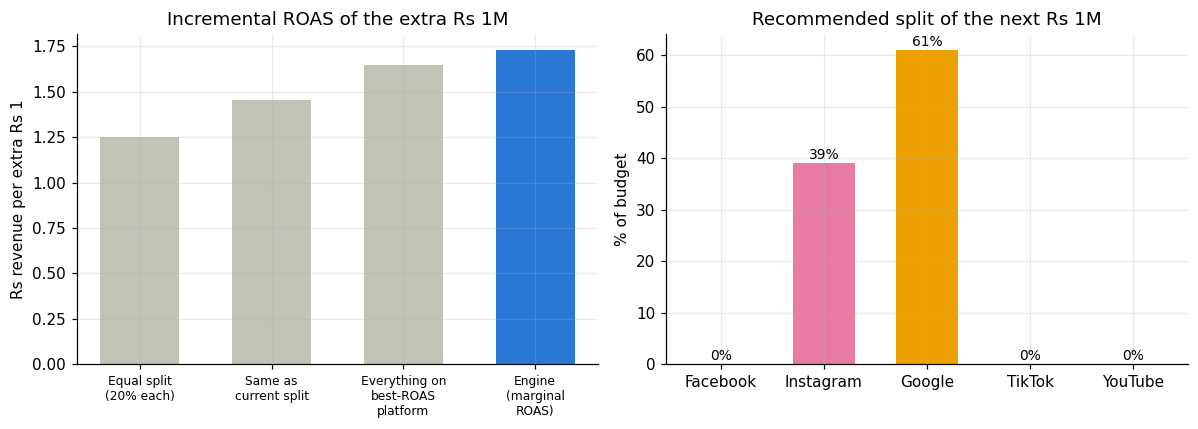

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(res.index, res["incremental_ROAS"], color=["#c3c2b7"] * 3 + ["#2a78d6"], width=.6)
import textwrap
ax[0].set_xticklabels([textwrap.fill(x, 14) for x in res.index], fontsize=8)
ax[0].set_title("Incremental ROAS of the extra Rs 1M"); ax[0].set_ylabel("Rs revenue per extra Rs 1")
ax[1].bar(reco.index, reco["share_%"], color=[PLAT_COLORS[p] for p in reco.index], width=.6)
for i, v in enumerate(reco["share_%"]): ax[1].text(i, v + .8, f"{v:.0f}%", ha="center", fontsize=9)
ax[1].set_title("Recommended split of the next Rs 1M"); ax[1].set_ylabel("% of budget")
plt.tight_layout(); plt.show()

## Step 5: Validate the engine (out-of-sample test)
A model that only fits the past proves nothing. We fit the curves on **weeks 0-41** and predict **weeks 42-52** (unseen). Metric: MAPE of weekly platform revenue.

In [18]:
train, test = wk[wk.week < 42], wk[wk.week >= 42]
cv = fit_curves(train)
test = test.copy()
test["pred"] = [cv.loc[p, "a"] * s ** cv.loc[p, "b"] for p, s in zip(test["platform"], test["spend"])]
test["ape"] = (test["pred"] - test["revenue"]).abs() / test["revenue"]
naive = train.groupby("platform", observed=True).apply(lambda g: g["revenue"].sum() / g["spend"].sum())
test["pred_naive"] = test["spend"] * test["platform"].map(naive).astype(float)
test["ape_naive"] = (test["pred_naive"] - test["revenue"]).abs() / test["revenue"]
print(f"MAPE, response-curve model : {test['ape'].mean()*100:.1f}%")
print(f"MAPE, constant-ROAS baseline: {test['ape_naive'].mean()*100:.1f}%")

MAPE, response-curve model : 17.8%
MAPE, constant-ROAS baseline: 20.7%


## Step 6: Which campaign to put the money behind (second layer)
Platform split answers *where*; the campaign x platform table answers *what to advertise there*.

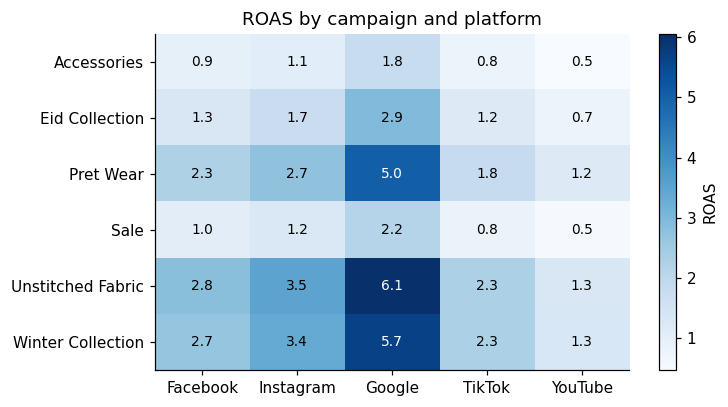

In [19]:
cp = add_kpis(hist.groupby(["platform", "campaign"], observed=True)[SUM_COLS].sum()).reset_index()
pivot = cp.pivot(index="campaign", columns="platform", values="ROAS")[PLATFORMS]
fig, ax = plt.subplots(figsize=(7, 3.8))
im = ax.imshow(pivot.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(5)); ax.set_xticklabels(PLATFORMS); ax.set_yticks(range(6)); ax.set_yticklabels(pivot.index); ax.grid(False)
for i in range(6):
    for j in range(5):
        v = pivot.values[i, j]; ax.text(j, i, f"{v:.1f}", ha="center", va="center", color="white" if v > pivot.values.max() * .6 else "black", fontsize=9)
ax.set_title("ROAS by campaign and platform"); plt.colorbar(im, label="ROAS"); plt.tight_layout(); plt.show()